### Keyword Spotting Training and Test

In [1]:
import random
from pathlib import Path

import numpy as np
import scipy
from scipy.io import wavfile
import tensorflow as tf
import tensorflow_model_optimization as tfmot
from sklearn.model_selection import train_test_split
import cmsisdsp
import cmsisdsp.mfcc

# ---------------- Configuration ----------------
TEST_SIZE = 0.2
SEED = 2

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


Define the 8 kHz, half-second audio windows and CMSIS-DSP Q15 mel-spectrogram pipeline used to match the Teensy implementation.


In [2]:
# ---------------- Audio preprocessing functions ----------------
DURATION = 0.5
SAMPLE_RATE = 8000
WINDOW_SIZE = int(SAMPLE_RATE * DURATION)
HOP_SIZE = WINDOW_SIZE // 2

N_FFT = 256
N_MELS = 16
FEATURE_FRAMES = 1 + (WINDOW_SIZE - N_FFT) // (N_FFT // 2)
fmin = 0
fmax = SAMPLE_RATE / 2

#------------cmsisdsp implementation of melspec------------
filter_lengths, filter_pos, filter_coefs = (
    cmsisdsp.mfcc.melFilterMatrix(
        cmsisdsp.mfcc.dt.Q15, fmin, fmax, N_MELS, SAMPLE_RATE, N_FFT
    )
)

window_coefs = scipy.signal.windows.hamming(N_FFT, sym=False)
def to_q15(v):
    return np.clip(np.round(v * 32768), -32768, 32767).astype(np.int16)
window_coefs = to_q15(window_coefs)

rfft_instance = cmsisdsp.arm_rfft_instance_q15()
status = cmsisdsp.arm_rfft_init_q15(rfft_instance, N_FFT, 0, 1)
assert status == 0

SAT_MIN = -(2**15)
SAT_MAX = 2**15 - 1
MICRO_Q15 = 0x00000219
SHIFT_MELFILTER_SATURATION_Q15 = 15

def cmsis_melspec(pSrc):
    output_data = cmsisdsp.arm_rfft_q15(rfft_instance, pSrc)
    output_data_sat = cmsisdsp.arm_shift_q15(output_data, 8)
    fft_mag = cmsisdsp.arm_cmplx_mag_squared_q15(output_data_sat)
    coefs_pos = 0
    results = []
    for i in range(N_MELS):
        n = filter_lengths[i]
        result = cmsisdsp.arm_dot_prod_q15(
            fft_mag[filter_pos[i]:filter_pos[i] + n],
            filter_coefs[coefs_pos:coefs_pos + n],
        )
        result += MICRO_Q15
        result >>= SHIFT_MELFILTER_SATURATION_Q15
        result = max(SAT_MIN, min(result, SAT_MAX))
        results.append(result)
        coefs_pos += filter_lengths[i]
    return results

def signal_melspec(x, frame_len=N_FFT, hop_len=N_FFT // 2):
    n_frames = 1 + (len(x) - frame_len) // hop_len
    result = []
    for i in range(n_frames):
        src_slice = x[i * hop_len:i * hop_len + frame_len].copy()
        windowed_frame = cmsisdsp.arm_mult_q15(src_slice, window_coefs)
        result.append(cmsis_melspec(windowed_frame))
    return np.stack(result, axis=-1)

#-------------end of MFCC implementation ------------------------------
def load_audio(path):
    sr, waveform = wavfile.read(path)
    print(sr, waveform.shape, type(waveform))
    assert sr == SAMPLE_RATE
    return waveform

def make_windows(waveform):
    return [
        waveform[start:start + WINDOW_SIZE]
        for start in range(0, len(waveform) - WINDOW_SIZE + 1, HOP_SIZE)
    ]

def extract_features(waveform):
    return np.asarray(signal_melspec(waveform), dtype=np.float32)


Load positive and negative recordings, augment their windowed audio, extract mel features, and create the training/validation split.


In [3]:
positive_train_list = [str(p) for p in Path("dataset/train/positive/").rglob("*")]
negative_train_list = [str(p) for p in Path("dataset/train/negative/").rglob("*")]
FILES = {1: positive_train_list, 0: negative_train_list}
NUM_GAIN_AUGMENTATIONS = 2
MAX_GAIN = 4
LABEL_NAMES = {0: "no_keyword", 1: "keyword"}

features = []
labels = []
for label, paths in FILES.items():
    for filename in paths:
        path = Path(filename)
        if not path.exists():
            raise FileNotFoundError(f"Audio file not found: {path.resolve()}")

        audio = load_audio(str(path))
        windows = make_windows(audio)
        print(
            f"{filename}: {len(audio) / SAMPLE_RATE:.2f}s, "
            f"{len(windows)} windows, label={LABEL_NAMES[label]}"
        )

        for window in windows:
            for i in range(NUM_GAIN_AUGMENTATIONS):
                random_gain = np.random.rand(1).item() * MAX_GAIN if i != 0 else 1
                window = window.astype(np.float32) * random_gain
                features.append(extract_features(window))
                labels.append(label)

# Features are converted from [frequency, frame] to TensorFlow NHWC layout.
features = np.asarray(features, dtype=np.float32)[..., np.newaxis]
labels = np.asarray(labels, dtype=np.float32)


X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.2, random_state=42, stratify=labels
)


8000 (337432,) <class 'numpy.ndarray'>
dataset\train\positive\hi.wav: 42.18s, 167 windows, label=keyword
8000 (320560,) <class 'numpy.ndarray'>
dataset\train\positive\hi_held.wav: 40.07s, 159 windows, label=keyword
8000 (484647,) <class 'numpy.ndarray'>
dataset\train\positive\hi_monotonic.wav: 60.58s, 241 windows, label=keyword
8000 (401705,) <class 'numpy.ndarray'>
dataset\train\positive\hi_variation.wav: 50.21s, 199 windows, label=keyword
8000 (486720,) <class 'numpy.ndarray'>
dataset\train\negative\ambience.wav: 60.84s, 242 windows, label=no_keyword
8000 (354480,) <class 'numpy.ndarray'>
dataset\train\negative\env_noise.wav: 44.31s, 176 windows, label=no_keyword
8000 (668240,) <class 'numpy.ndarray'>
dataset\train\negative\giberish.wav: 83.53s, 333 windows, label=no_keyword
8000 (334828,) <class 'numpy.ndarray'>
dataset\train\negative\mouth_noise.wav: 41.85s, 166 windows, label=no_keyword
8000 (497743,) <class 'numpy.ndarray'>
dataset\train\negative\other_words.wav: 62.22s, 247 wind

Build the compact LeNet-inspired convolutional binary classifier for the keyword and non-keyword classes.


In [4]:
# ---------------- TensorFlow model ----------------
def build_keyword_cnn():
    inputs = tf.keras.Input(shape=(N_MELS, FEATURE_FRAMES, 1))

    x = tf.keras.layers.Conv2D(4, kernel_size=3, padding="same")(inputs)
    x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=2)(x)

    x = tf.keras.layers.Conv2D(8, kernel_size=3, padding="same")(x)
    x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=2)(x)

    x = tf.keras.layers.Conv2D(16, kernel_size=3, padding="same")(x)
    x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.AveragePooling2D(pool_size=3, strides=2)(x)

    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(32)(x)
    x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    return tf.keras.Model(inputs=inputs, outputs=outputs, name="keyword_cnn")

def evaluate(model, features, labels):
    loss, accuracy = model.evaluate(features, labels, verbose=0)
    return loss, 100.0 * accuracy

def count_parameters(model):
    print(f"Total parameters: {model.count_params():,}")


Train the classifier with quantization-aware training (QAT) for 100 epochs and save checkpoints for later comparison.


In [5]:
losses = []
BATCH_SIZE = 32
EPOCHS = 100
LEARNING_RATE = 1e-3
TF_CHECKPOINT_DIR = Path("tf_ckpts")
TF_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

class SaveQATWeightsEveryNEpochs(tf.keras.callbacks.Callback):
    def __init__(self, checkpoint_dir, interval=10):
        super().__init__()
        self.checkpoint_dir = Path(checkpoint_dir)
        self.interval = interval

    def on_epoch_end(self, epoch, logs=None):
        completed_epoch = epoch + 1
        if completed_epoch % self.interval == 0:
            checkpoint_path = self.checkpoint_dir / f"qat_epoch_{completed_epoch:03d}.weights.h5"
            self.model.save_weights(checkpoint_path)
            print(f"Saved QAT checkpoint: {checkpoint_path}")

print("Training TensorFlow model with quantization-aware training...")
float_model = build_keyword_cnn()
qat_model = tfmot.quantization.keras.quantize_model(float_model)
qat_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
count_parameters(qat_model)

checkpoint_callback = SaveQATWeightsEveryNEpochs(TF_CHECKPOINT_DIR, interval=10)
history = qat_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=[checkpoint_callback],
    verbose=1,
)
model = qat_model

losses = np.column_stack((history.history["loss"], history.history["val_loss"]))
best_test_acc = 100.0 * max(history.history["val_accuracy"])
print(f"Best test accuracy: {best_test_acc:.2f}%")
print(f"QAT checkpoints saved in: {TF_CHECKPOINT_DIR.resolve()}")

Training TensorFlow model with quantization-aware training...


Total parameters: 3,136
Epoch 1/100


163/163 [==============================] - 3s 6ms/step - loss: 0.4990 - accuracy: 0.7666 - val_loss: 0.3692 - val_accuracy: 0.8183
Epoch 2/100
163/163 [==============================] - 1s 4ms/step - loss: 0.3797 - accuracy: 0.8319 - val_loss: 0.3459 - val_accuracy: 0.8460
Epoch 3/100
163/163 [==============================] - 1s 4ms/step - loss: 0.3991 - accuracy: 0.8250 - val_loss: 0.3545 - val_accuracy: 0.8306
Epoch 4/100
163/163 [==============================] - 1s 4ms/step - loss: 0.4371 - accuracy: 0.8097 - val_loss: 0.3494 - val_accuracy: 0.8360
Epoch 5/100
163/163 [==============================] - 1s 4ms/step - loss: 0.3673 - accuracy: 0.8228 - val_loss: 0.3850 - val_accuracy: 0.8306
Epoch 6/100
163/163 [==============================] - 1s 4ms/step - loss: 0.3977 - accuracy: 0.8234 - val_loss: 0.3920 - val_accuracy: 0.8422
Epoch 7/100
163/163 [==============================]

Plot training and validation loss across epochs to inspect convergence and possible overfitting.


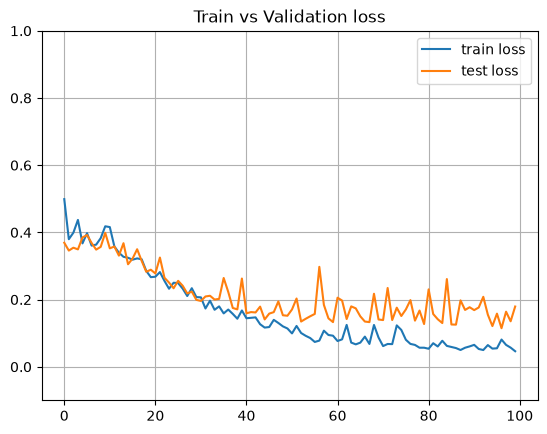

In [10]:
from matplotlib import pyplot as plt
plt.plot(losses[:, 0], label="train loss")
plt.plot(losses[:, 1], label="test loss")
plt.ylim(-0.1, 1)
plt.title("Train vs Validation loss")
plt.legend()
plt.axis()
plt.grid()


Load the epoch-100 QAT checkpoint selected for the held-out tests and subsequent INT8 conversion.


In [17]:
model = qat_model
SELECTED_QAT_CHECKPOINT = TF_CHECKPOINT_DIR / "qat_epoch_100.weights.h5"
if not SELECTED_QAT_CHECKPOINT.exists():
    raise FileNotFoundError(f"Checkpoint not found: {SELECTED_QAT_CHECKPOINT}")

model.load_weights(str(SELECTED_QAT_CHECKPOINT))
print(f"Loaded QAT checkpoint: {SELECTED_QAT_CHECKPOINT}")

Loaded QAT checkpoint: tf_ckpts\qat_epoch_100.weights.h5


Prepare the separate positive and negative recordings as held-out windows for keyword-spotting evaluation.


In [18]:
FILES = {
    1: ["hi_test.wav"],
    0: ["giberish_test.wav"],
}
LABEL_NAMES = {0: "no_keyword", 1: "keyword"}

features_test = []
labels_test = []
for label, paths in FILES.items():
    for filename in paths:
        path = Path(filename)
        if not path.exists():
            raise FileNotFoundError(f"Audio file not found: {path.resolve()}")

        audio = load_audio(str(path))
        windows = make_windows(audio)
        print(
            f"{filename}: {len(audio) / SAMPLE_RATE:.2f}s, "
            f"{len(windows)} windows, label={LABEL_NAMES[label]}"
        )
        for window in windows:
            features_test.append(extract_features(window))
            labels_test.append(label)

features_test = np.asarray(features_test, dtype=np.float32)[..., np.newaxis]
labels_test = np.asarray(labels_test, dtype=np.float32)


8000 (114560,) <class 'numpy.ndarray'>
hi_test.wav: 14.32s, 56 windows, label=keyword
8000 (360720,) <class 'numpy.ndarray'>
giberish_test.wav: 45.09s, 179 windows, label=no_keyword


Evaluate held-out QAT predictions with the ROC curve and select a decision threshold at the target false-positive rate.


0.5


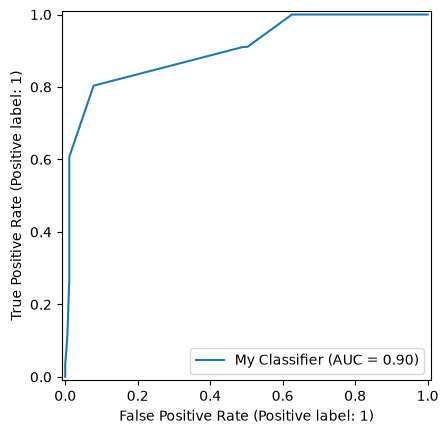

In [19]:
from sklearn.metrics import RocCurveDisplay, roc_curve

y_pred = model.predict(features_test, verbose=0).reshape(-1)
y_true = labels_test
RocCurveDisplay.from_predictions(y_true, y_pred, name="My Classifier")

fpr, tpr, thresholds = roc_curve(y_true, y_pred)
target_fpr = 0.05
idx_fpr = np.where(fpr <= target_fpr)[0][-1]
chosen_threshold_fpr = thresholds[idx_fpr]
print(chosen_threshold_fpr)


Plot the precision-recall curve to examine the trade-off between keyword detections and false alarms.


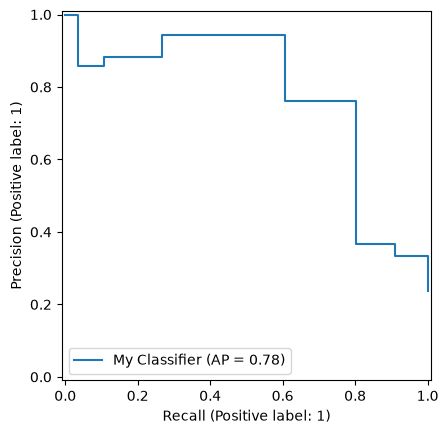

In [21]:
from sklearn.metrics import PrecisionRecallDisplay
PrecisionRecallDisplay.from_predictions(y_true, y_pred, name="My Classifier")


Run the QAT model over the negative test recording and align overlapping window scores across the audio timeline.


In [ ]:
test_gain = 8
sr, test_audio = wavfile.read("giberish_test.wav")
windows = make_windows(test_audio * test_gain)
feats = [extract_features(window) for window in windows]
input_vec = np.asarray(feats, dtype=np.float32)[..., np.newaxis]
labels = model.predict(input_vec, verbose=0).reshape(-1)

label_array = np.zeros_like(test_audio, dtype=np.float32)
overlap_array = label_array.copy()
for i, label in enumerate(labels):
    start = HOP_SIZE * i
    end = start + WINDOW_SIZE
    label_array[start:end] += label
    overlap_array[start:end] += 1

label_array_result = np.divide(
    label_array,
    overlap_array,
    out=np.zeros_like(label_array),
    where=overlap_array != 0,
)


Visualize window-level detection scores alongside the test waveform to inspect false activations over time.


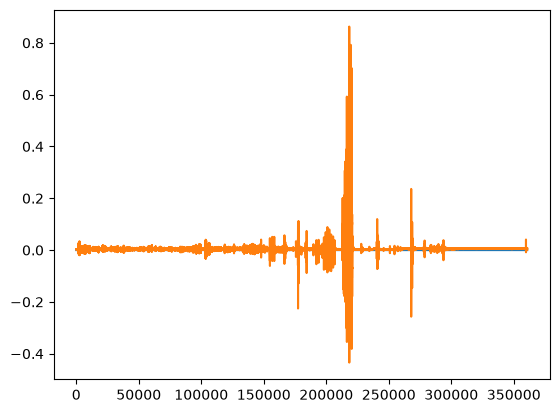

In [16]:
from matplotlib import pyplot as plt
plt.plot(label_array_result)
plt.plot(test_audio / 32768)


Record a TensorFlow QAT prediction on one feature sample for comparison with quantized TFLite inference.


In [17]:
probe_feat = features[:1]
test_output_tf = model.predict(probe_feat, verbose=0).item()
print("TensorFlow QAT model output:", test_output_tf)


TensorFlow QAT model output: 0.04631001874804497


Full-integer TFLite conversion. The resulting FlatBuffer stays in memory.
TFLite Micro int8 kernels use signed int8 weights/activations and int32 bias accumulators; Conv2D weights are quantized per output channel.


In [18]:
converter = tf.lite.TFLiteConverter.from_keras_model(qat_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

def representative_dataset():
    for sample in X_train[:300]:
        yield [sample[np.newaxis, ...].astype(np.float32)]

converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
tflite_model = converter.convert()

OUTPUT_TFLITE_PATH = Path("keyword_model_qat_int8.tflite")
OUTPUT_TFLITE_PATH.write_bytes(tflite_model)
print(f"Saved TFLite model to: {OUTPUT_TFLITE_PATH}")

interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
assert input_details[0]["dtype"] == np.int8
assert output_details[0]["dtype"] == np.int8


INFO:tensorflow:Assets written to: C:\Users\bfgod\AppData\Local\Temp\tmpgknxx_yw\assets


INFO:tensorflow:Assets written to: C:\Users\bfgod\AppData\Local\Temp\tmpgknxx_yw\assets
C:\Users\bfgod\miniconda3\envs\arduino_ml\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Saved TFLite model to: keyword_model_qat_int8.tflite


C:\Users\bfgod\miniconda3\envs\arduino_ml\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [19]:
print("In-memory full-integer TFLite model bytes:", len(tflite_model))
print("Input quantization:", input_details[0]["quantization"])
print("Output quantization:", output_details[0]["quantization"])


In-memory full-integer TFLite model bytes: 10384
Input quantization: (128.49803161621094, -128)
Output quantization: (0.00390625, -128)


Run one held-out sample through the INT8 interpreter and convert its quantized output back to a probability.


In [26]:
input_scale, input_zero_point = input_details[0]["quantization"]
output_scale, output_zero_point = output_details[0]["quantization"]
assert input_scale > 0 and output_scale > 0
# dirty compatibility check for scale of 128 instead of 128.5
input_scale = 128
# -0.02 auc (0.8 against 0.78)
sample = features_test[:1]
quantized_sample = np.round(sample / input_scale + input_zero_point)
quantized_sample = np.clip(quantized_sample, -128, 127).astype(np.int8)
interpreter.set_tensor(input_details[0]["index"], quantized_sample)
interpreter.invoke()
quantized_output = interpreter.get_tensor(output_details[0]["index"])
tflite_probability = (
    quantized_output.astype(np.float32) - output_zero_point
) * output_scale
print("TFLite int8 output:", tflite_probability.reshape(-1))


TFLite int8 output: [0.5]


Check that the TFLite graph uses the expected tensors, accumulators and operators for fixed-point inference.


In [27]:
tensor_details = interpreter.get_tensor_details()
int8_tensors = [item for item in tensor_details if item["dtype"] == np.int8]
int32_tensors = [item for item in tensor_details if item["dtype"] == np.int32]
assert int8_tensors, "Expected int8 TFLite tensors"
assert int32_tensors, "Expected int32 TFLite accumulator/bias tensors"
print("TFLite INT8 tensors:", len(int8_tensors))
print("TFLite INT32 accumulator/bias tensors:", len(int32_tensors))
print("TFLite operators:", [item["op_name"] for item in interpreter._get_ops_details()])


TFLite INT8 tensors: 17
TFLite INT32 accumulator/bias tensors: 6
TFLite operators: ['CONV_2D', 'MAX_POOL_2D', 'CONV_2D', 'MAX_POOL_2D', 'CONV_2D', 'AVERAGE_POOL_2D', 'QUANTIZE', 'RESHAPE', 'FULLY_CONNECTED', 'FULLY_CONNECTED', 'LOGISTIC', 'DELEGATE', 'DELEGATE']


Evaluate the full-int8 TFLite model on held-out data and compare its ROC behavior and threshold with the QAT model.


TFLite INT8 threshold at target FPR: 0.953125


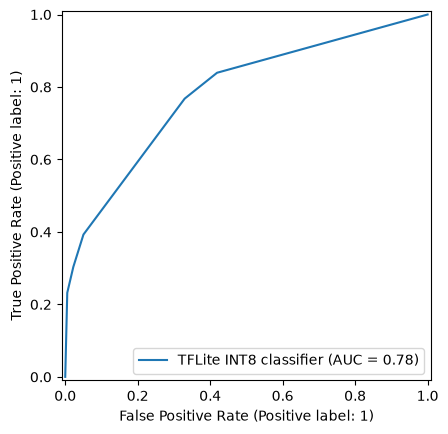

In [28]:
# ROC evaluation using predictions from the full-int8 TFLite interpreter.
quantized_y_pred = []
for feature_sample in features_test:
    quantized_input = np.round(
        feature_sample[np.newaxis, ...] / input_scale + input_zero_point
    )
    quantized_input = np.clip(quantized_input, -128, 127).astype(np.int8)
    interpreter.set_tensor(input_details[0]["index"], quantized_input)
    interpreter.invoke()
    quantized_result = interpreter.get_tensor(output_details[0]["index"])
    probability = (
        quantized_result.astype(np.float32) - output_zero_point
    ) * output_scale
    quantized_y_pred.append(probability.reshape(-1)[0])

quantized_y_pred = np.asarray(quantized_y_pred, dtype=np.float32)
RocCurveDisplay.from_predictions(
    labels_test,
    quantized_y_pred,
    name="TFLite INT8 classifier",
)
quantized_fpr, quantized_tpr, quantized_thresholds = roc_curve(
    labels_test, quantized_y_pred
)
quantized_idx_fpr = np.where(quantized_fpr <= target_fpr)[0][-1]
quantized_chosen_threshold_fpr = quantized_thresholds[quantized_idx_fpr]
print("TFLite INT8 threshold at target FPR:", quantized_chosen_threshold_fpr)


Print the TFLite input, output, and tensor metadata needed to integrate model I/O into the Teensy MicroTFLite firmware.


In [86]:
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
all_tensors = interpreter.get_tensor_details()

# Create lookup maps for identification
input_indexes = {d['index'] for d in input_details}
output_indexes = {d['index'] for d in output_details}

print("=" * 90)
print(f"VERBOSE TFLITE TENSOR SPECIFICATION ANALYSIS")
print("=" * 90)

# 1. PRINT MODEL ENTRANCE/EXIT PORTS
print("\n--- [ MODEL INPUTS ] ---")
for i, detail in enumerate(input_details):
    print(f"Input #{i} | Index: {detail['index']:<3} | Name: '{detail['name']}'")
    print(f"  -> Shape: {detail['shape']} | DataType: {detail['dtype']}")
    print(f"  -> Quantization (Scale, ZeroPoint): {detail['quantization']}")

print("\n--- [ MODEL OUTPUTS ] ---")
for i, detail in enumerate(output_details):
    print(f"Output #{i} | Index: {detail['index']:<3} | Name: '{detail['name']}'")
    print(f"  -> Shape: {detail['shape']} | DataType: {detail['dtype']}")
    print(f"  -> Quantization (Scale, ZeroPoint): {detail['quantization']}")

# 2. PRINT INTERNAL PARAMETERS & LAYER TENSORS
print("\n--- [ INTERNAL LAYER PARAMETERS & INTERMEDIATE ACTIVATIONS ] ---")
print(f"{'Tensor Name':<45} | {'Index':<5} | {'Shape':<15} | {'DataType':<12} | {'Role Hint':<10}")
print("-" * 95)

for detail in all_tensors:
    idx = detail['index']
    
    # Skip printing boundary inputs/outputs here since they are printed above
    if idx in input_indexes or idx in output_indexes:
        continue
        
    name = detail['name']
    dtype = detail['dtype']
    shape = str(detail['shape'])
    
    # Infer the structural role of the tensor from its name
    role = "Activation"
    if "bias" in name.lower():
        role = "Bias (int32)"
    elif "weight" in name.lower() or "kernel" in name.lower() or "filter" in name.lower():
        role = "Weight"
        
    print(f"{name[:45]:<45} | {idx:<5} | {shape:<15} | {str(dtype):<12} | {role:<10}")

print("=" * 95)
print("\n* Verification Note: Weights and Intermediate Activations should read 'int8'.")
print("* Verification Note: Biases safely accumulate math in 'int32'.")

VERBOSE TFLITE TENSOR SPECIFICATION ANALYSIS

--- [ MODEL INPUTS ] ---
Input #0 | Index: 0   | Name: 'serving_default_input_1:0'
  -> Shape: [ 1 16 30  1] | DataType: <class 'numpy.int8'>
  -> Quantization (Scale, ZeroPoint): (128.49803161621094, -128)

--- [ MODEL OUTPUTS ] ---
Output #0 | Index: 22  | Name: 'StatefulPartitionedCall:0'
  -> Shape: [1 1] | DataType: <class 'numpy.int8'>
  -> Quantization (Scale, ZeroPoint): (0.00390625, -128)

--- [ INTERNAL LAYER PARAMETERS & INTERMEDIATE ACTIVATIONS ] ---
Tensor Name                                   | Index | Shape           | DataType     | Role Hint 
-----------------------------------------------------------------------------------------------
arith.constant                                | 1     | [2]             | <class 'numpy.int32'> | Activation
keyword_cnn/quant_conv2d/Conv2D               | 2     | [4 3 3 1]       | <class 'numpy.int8'> | Activation
keyword_cnn/quant_re_lu/Relu;keyword_cnn/quan | 3     | [4]             | 